# 🔢 Reconnaissance de Chiffres Manuscrits — MNIST avec MLP PyTorch

**Objectif** : Construire un pipeline complet sur le dataset MNIST (70 000 images de chiffres manuscrits 0–9) avec un **MLP PyTorch** sans CNN.

| Élément | Détail |
|---|---|
| **Type** | Classification multi-classes (10 classes : 0 à 9) |
| **Dataset** | MNIST — 60 000 train / 10 000 test |
| **Input** | Image 28×28 → vecteur aplati de 784 pixels |
| **Architecture** | MLP : 784 → 512 → 256 → 128 → 10 |
| **Régularisation** | BatchNorm + Dropout |
| **Loss** | CrossEntropyLoss |
| **Optimizer** | Adam + ReduceLROnPlateau |
| **Métriques** | Accuracy, Matrice de confusion, Rapport de classification |

## 1. Import des bibliothèques

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Sklearn — métriques
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

# Reproductibilité
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {device}")
print(f"PyTorch : {torch.__version__}")
print("Bibliothèques importées ✔")

Device  : cuda
PyTorch : 2.4.1+cu124
Bibliothèques importées ✔


## 2. Chargement de MNIST & Visualisation des images

In [2]:
# Transformation : PIL → Tensor, puis normalisation (μ=0.1307, σ=0.3081 — valeurs MNIST officielles)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Téléchargement automatique (dossier ./data/)
train_full = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_ds    = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

print(f"Train complet : {len(train_full)} images")
print(f"Test          : {len(test_ds)} images")
print(f"Classes       : {train_full.classes}")
print(f"Shape image   : {train_full[0][0].shape}  (C × H × W)")

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:12<00:00, 822849.88it/s] 


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 273655.89it/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:02<00:00, 626271.52it/s]


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 2274961.64it/s]

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw

Train complet : 60000 images
Test          : 10000 images
Classes       : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Shape image   : torch.Size([1, 28, 28])  (C × H × W)


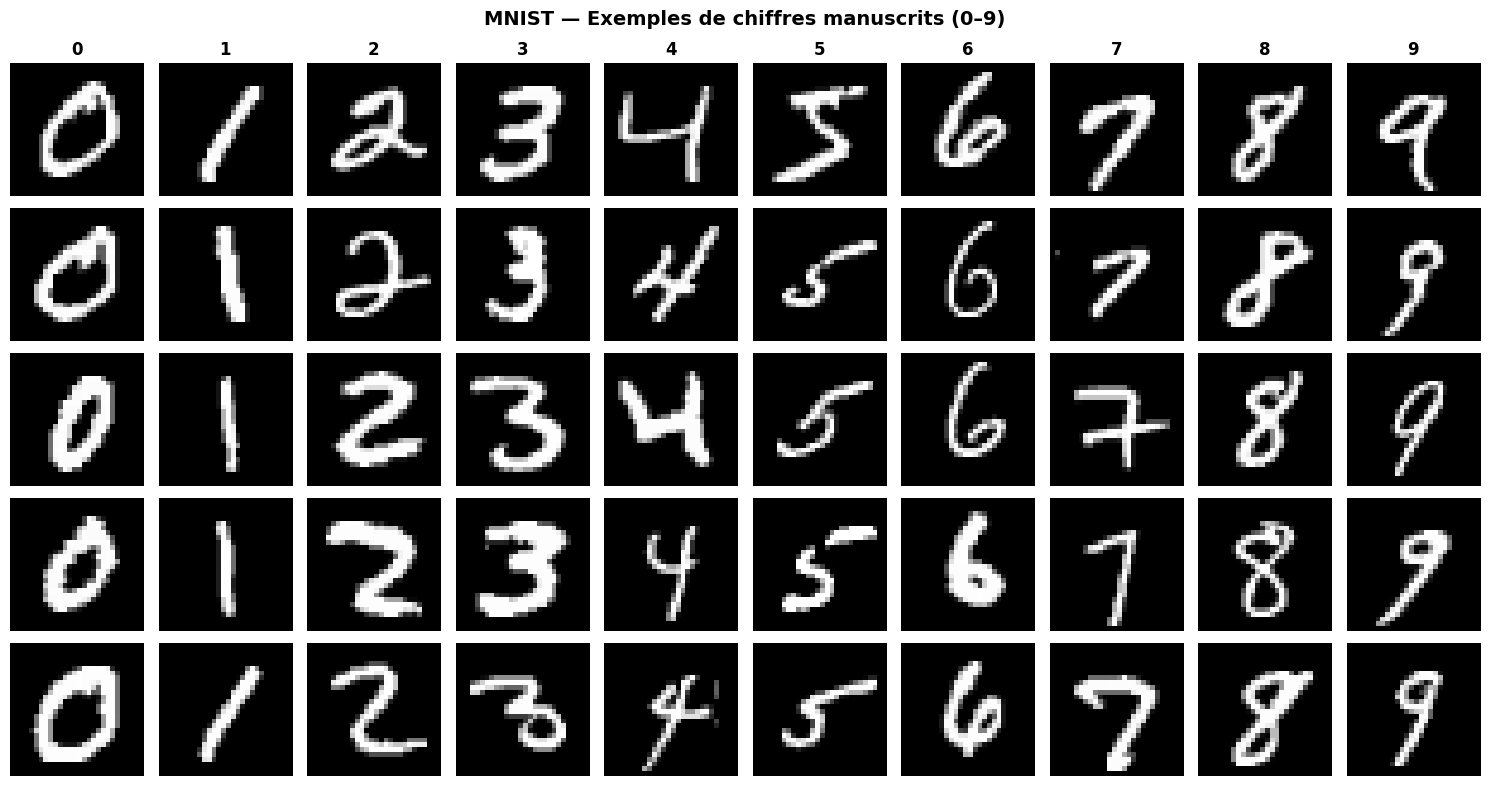

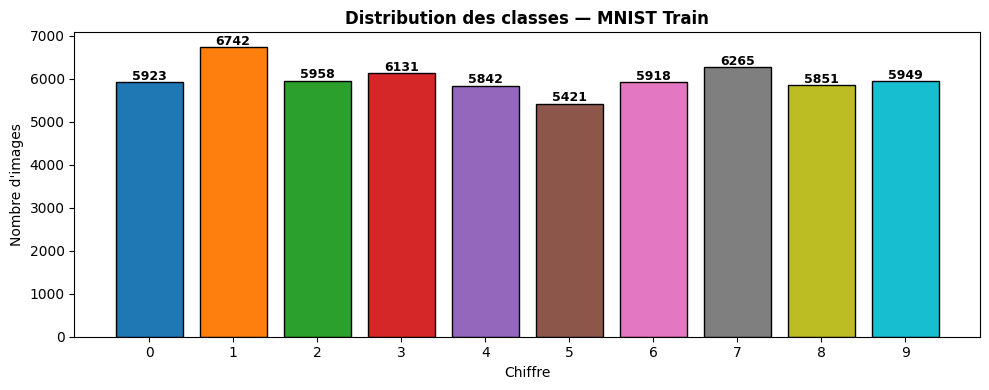

Classes équilibrées : min=5421, max=6742


In [3]:
# ─── Visualisation : grille 5×10 (un exemple par chiffre par ligne) ──────────
fig, axes = plt.subplots(5, 10, figsize=(15, 8))
fig.suptitle('MNIST — Exemples de chiffres manuscrits (0–9)', fontsize=14, fontweight='bold')

# Chercher des exemples pour chaque label
shown = {i: 0 for i in range(10)}
row   = 0
for img, label in train_full:
    col = label
    if shown[col] < 5:
        ax = axes[shown[col]][col]
        ax.imshow(img.squeeze(), cmap='gray')
        ax.axis('off')
        if shown[col] == 0:
            ax.set_title(str(col), fontsize=12, fontweight='bold')
        shown[col] += 1
    if all(v == 5 for v in shown.values()):
        break

plt.tight_layout()
plt.savefig('mnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()

# ─── Distribution des classes ─────────────────────────────────────────────────
labels_train = [train_full[i][1] for i in range(len(train_full))]
fig2, ax = plt.subplots(figsize=(10, 4))
counts = [labels_train.count(i) for i in range(10)]
bars = ax.bar(range(10), counts, color=plt.cm.tab10.colors, edgecolor='black')
ax.set_xlabel('Chiffre'); ax.set_ylabel('Nombre d\'images')
ax.set_title('Distribution des classes — MNIST Train', fontweight='bold')
ax.set_xticks(range(10))
for bar, cnt in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(cnt), ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Classes équilibrées : min={min(counts)}, max={max(counts)}")

## 3. Préparation des DataLoaders (Train / Validation / Test)

In [4]:
BATCH_SIZE = 128
VAL_SIZE   = 6000    # 10% du train pour la validation

# Split train → train / val
train_ds, val_ds = random_split(
    train_full, [len(train_full) - VAL_SIZE, VAL_SIZE],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Batch size      : {BATCH_SIZE}")
print(f"Train samples   : {len(train_ds)}")
print(f"Val   samples   : {len(val_ds)}")
print(f"Test  samples   : {len(test_ds)}")
print(f"Train batches   : {len(train_loader)}")

# Aperçu d'un batch
X_batch, y_batch = next(iter(train_loader))
print(f"\nShape d'un batch X : {X_batch.shape}  (batch × C × H × W)")
print(f"Shape d'un batch y : {y_batch.shape}")

Batch size      : 128
Train samples   : 54000
Val   samples   : 6000
Test  samples   : 10000
Train batches   : 422

Shape d'un batch X : torch.Size([128, 1, 28, 28])  (batch × C × H × W)
Shape d'un batch y : torch.Size([128])


## 4. Architecture du MLP

> Les images MNIST (28×28 pixels) sont **aplaties** en un vecteur de 784 valeurs avant d'entrer dans le réseau.  
> Aucun CNN n'est utilisé — uniquement des couches `Linear` (denses).

```
Input : 784  (= 28 × 28, aplati)
  ↓
Dense(512) → BatchNorm1d → ReLU → Dropout(0.4)
  ↓
Dense(256) → BatchNorm1d → ReLU → Dropout(0.3)
  ↓
Dense(128) → BatchNorm1d → ReLU → Dropout(0.2)
  ↓
Dense(10)  →  Softmax via CrossEntropyLoss
```

In [5]:
class MNISTClassifier(nn.Module):
    """MLP pour la classification des chiffres MNIST (0–9). Pas de CNN."""

    def __init__(self, input_dim=784, num_classes=10):
        super(MNISTClassifier, self).__init__()

        self.flatten = nn.Flatten()   # (B, 1, 28, 28) → (B, 784)

        self.network = nn.Sequential(
            # Couche 1 : 784 → 512
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),

            # Couche 2 : 512 → 256
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Couche 3 : 256 → 128
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Sortie : 128 → 10  (Softmax implicite via CrossEntropyLoss)
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)


model = MNISTClassifier().to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nParamètres entraînables : {total_params:,}")

MNISTClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=128, out_features=10, bias=True)
  )
)

Paramètres entraînables : 569,226


## 5. Entraînement — CrossEntropyLoss · Adam · Early Stopping

In [6]:
# ─── Hyperparamètres ──────────────────────────────────────────────────────────
EPOCHS   = 50
LR       = 1e-3
PATIENCE = 10

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, verbose=True)

# ─── Fonctions train / eval ────────────────────────────────────────────────────
def run_epoch(model, loader, criterion, optimizer, device, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for X_b, y_b in loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(X_b)
            loss   = criterion(logits, y_b)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y_b)
            preds = logits.argmax(dim=1)
            correct += (preds == y_b).sum().item()
            total   += len(y_b)
    return total_loss / total, correct / total

# ─── Boucle d'entraînement ────────────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss    = float('inf')
patience_counter = 0

print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 56)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, device, train=True)
    vl_loss, vl_acc = run_epoch(model, val_loader,   criterion, optimizer, device, train=False)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>6} | {tr_loss:>10.4f} | {tr_acc*100:>8.2f}% | {vl_loss:>8.4f} | {vl_acc*100:>6.2f}%")

    if vl_loss < best_val_loss:
        best_val_loss    = vl_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'mlp_mnist_best.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹ Early stopping à l'epoch {epoch}")
            break

print(f"\n✅ Terminé — Meilleur val_loss : {best_val_loss:.4f}")

 Epoch | Train Loss | Train Acc | Val Loss | Val Acc
--------------------------------------------------------
     1 |     0.3278 |    91.20% |   0.1278 |  96.23%
     5 |     0.0924 |    97.11% |   0.0705 |  97.75%
    10 |     0.0668 |    97.83% |   0.0683 |  98.08%
    15 |     0.0550 |    98.21% |   0.0586 |  98.25%
    20 |     0.0480 |    98.54% |   0.0546 |  98.28%
    25 |     0.0452 |    98.54% |   0.0637 |  98.05%
    30 |     0.0452 |    98.58% |   0.0637 |  98.10%
    35 |     0.0248 |    99.23% |   0.0505 |  98.52%
    40 |     0.0234 |    99.24% |   0.0523 |  98.53%
    45 |     0.0132 |    99.60% |   0.0507 |  98.53%
    50 |     0.0125 |    99.59% |   0.0501 |  98.52%

✅ Terminé — Meilleur val_loss : 0.0474


## 6. Courbes de Loss & Accuracy (train vs validation)

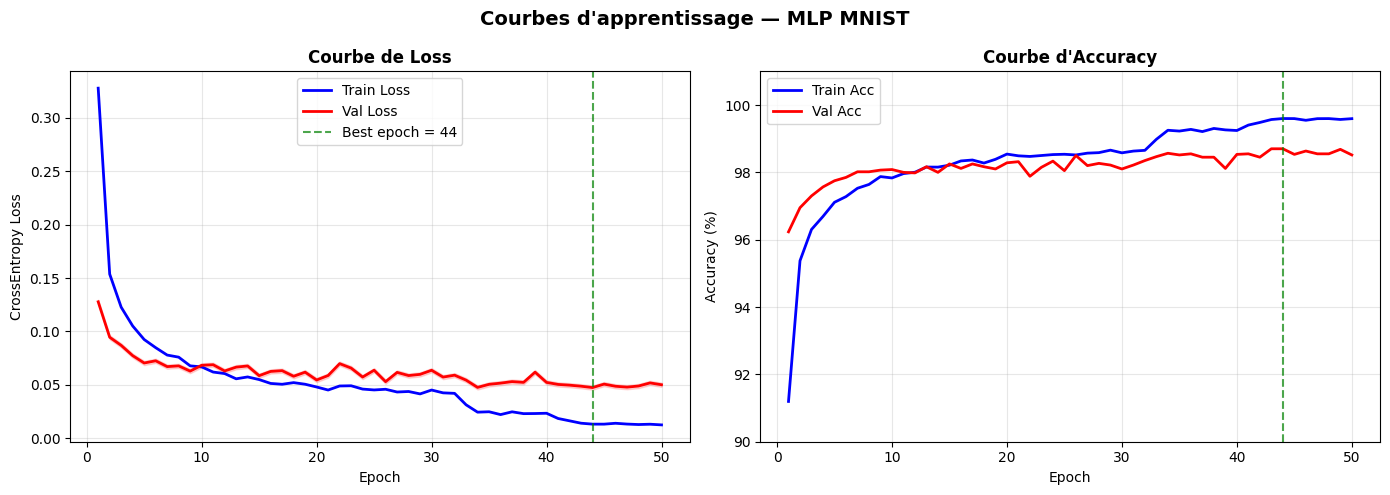

Meilleur epoch   : 44
Meilleur val_loss : 0.0474
Meilleur val_acc  : 98.70%


In [7]:
epochs_ran = range(1, len(history['train_loss']) + 1)
best_ep    = np.argmin(history['val_loss']) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Loss ──────────────────────────────────────────────────────────────────────
ax1.plot(epochs_ran, history['train_loss'], 'b-',  label='Train Loss', linewidth=2)
ax1.plot(epochs_ran, history['val_loss'],   'r-',  label='Val Loss',   linewidth=2)
ax1.axvline(best_ep, color='green', linestyle='--', alpha=0.7, label=f'Best epoch = {best_ep}')
ax1.fill_between(epochs_ran,
                 [l - 0.002 for l in history['val_loss']],
                 [l + 0.002 for l in history['val_loss']],
                 alpha=0.15, color='red')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('CrossEntropy Loss')
ax1.set_title('Courbe de Loss', fontweight='bold')
ax1.legend(); ax1.grid(True, alpha=0.3)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax2.plot(epochs_ran, [a*100 for a in history['train_acc']], 'b-', label='Train Acc', linewidth=2)
ax2.plot(epochs_ran, [a*100 for a in history['val_acc']],   'r-', label='Val Acc',   linewidth=2)
ax2.axvline(best_ep, color='green', linestyle='--', alpha=0.7)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title("Courbe d'Accuracy", fontweight='bold')
ax2.set_ylim(90, 101)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle("Courbes d'apprentissage — MLP MNIST", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('mnist_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Meilleur epoch   : {best_ep}")
print(f"Meilleur val_loss : {min(history['val_loss']):.4f}")
print(f"Meilleur val_acc  : {max(history['val_acc'])*100:.2f}%")

## 7. Évaluation sur le jeu de test — Accuracy · Matrice de confusion · Rapport

In [8]:
# Charger le meilleur modèle
model.load_state_dict(torch.load('mlp_mnist_best.pth', map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        preds = model(X_b).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_b.numpy())

y_pred = np.array(all_preds)
y_true = np.array(all_labels)

test_acc = accuracy_score(y_true, y_pred)
print(f"{'='*45}")
print(f"  TEST ACCURACY : {test_acc*100:.2f}%")
print(f"{'='*45}\n")
print("=== Rapport de classification ===")
print(classification_report(y_true, y_pred,
      target_names=[str(i) for i in range(10)], digits=4))

  TEST ACCURACY : 98.68%

=== Rapport de classification ===
              precision    recall  f1-score   support

           0     0.9918    0.9918    0.9918       980
           1     0.9921    0.9947    0.9934      1135
           2     0.9799    0.9913    0.9855      1032
           3     0.9881    0.9901    0.9891      1010
           4     0.9798    0.9857    0.9827       982
           5     0.9876    0.9854    0.9865       892
           6     0.9906    0.9864    0.9885       958
           7     0.9863    0.9796    0.9829      1028
           8     0.9886    0.9825    0.9856       974
           9     0.9831    0.9792    0.9811      1009

    accuracy                         0.9868     10000
   macro avg     0.9868    0.9867    0.9867     10000
weighted avg     0.9868    0.9868    0.9868     10000



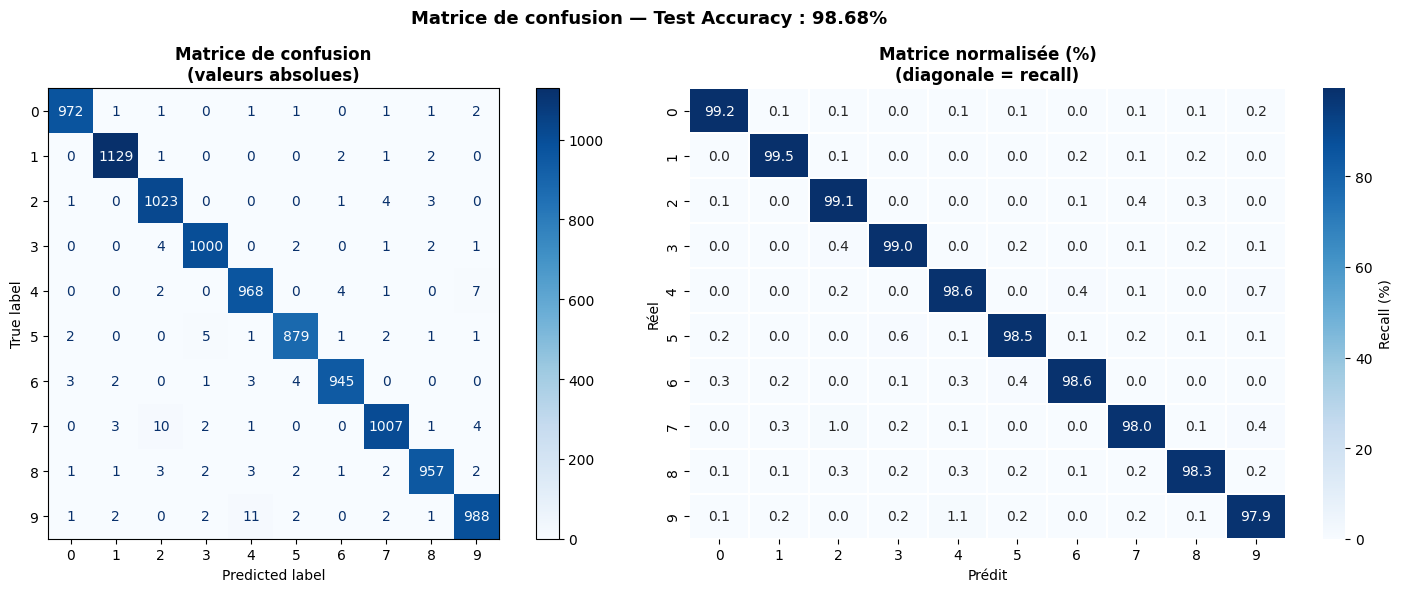

Paires de chiffres les plus confondues :
  Réel=9 prédit comme 4 : 11 fois
  Réel=7 prédit comme 2 : 10 fois
  Réel=4 prédit comme 9 : 7 fois
  Réel=5 prédit comme 3 : 5 fois
  Réel=7 prédit comme 9 : 4 fois
  Réel=6 prédit comme 5 : 4 fois
  Réel=4 prédit comme 6 : 4 fois
  Réel=3 prédit comme 2 : 4 fois


In [9]:
# ─── Matrice de confusion ─────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Absolue
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=list(range(10)))
disp.plot(ax=axes[0], colorbar=True, cmap='Blues')
axes[0].set_title('Matrice de confusion\n(valeurs absolues)', fontweight='bold')

# Normalisée (recall par ligne)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=list(range(10)),
            yticklabels=list(range(10)),
            ax=axes[1], linewidths=0.3,
            cbar_kws={'label': 'Recall (%)'})
axes[1].set_xlabel('Prédit'); axes[1].set_ylabel('Réel')
axes[1].set_title('Matrice normalisée (%)\n(diagonale = recall)', fontweight='bold')

plt.suptitle(f'Matrice de confusion — Test Accuracy : {test_acc*100:.2f}%',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('mnist_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Classes les plus confondues
print("Paires de chiffres les plus confondues :")
errors = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            errors.append((cm[i, j], i, j))
errors.sort(reverse=True)
for cnt, true_c, pred_c in errors[:8]:
    print(f"  Réel={true_c} prédit comme {pred_c} : {cnt} fois")

## 8. Analyse des erreurs — Visualisation des images mal classifiées

Images mal classifiées : 132 / 10000
Taux d'erreur          : 1.32%


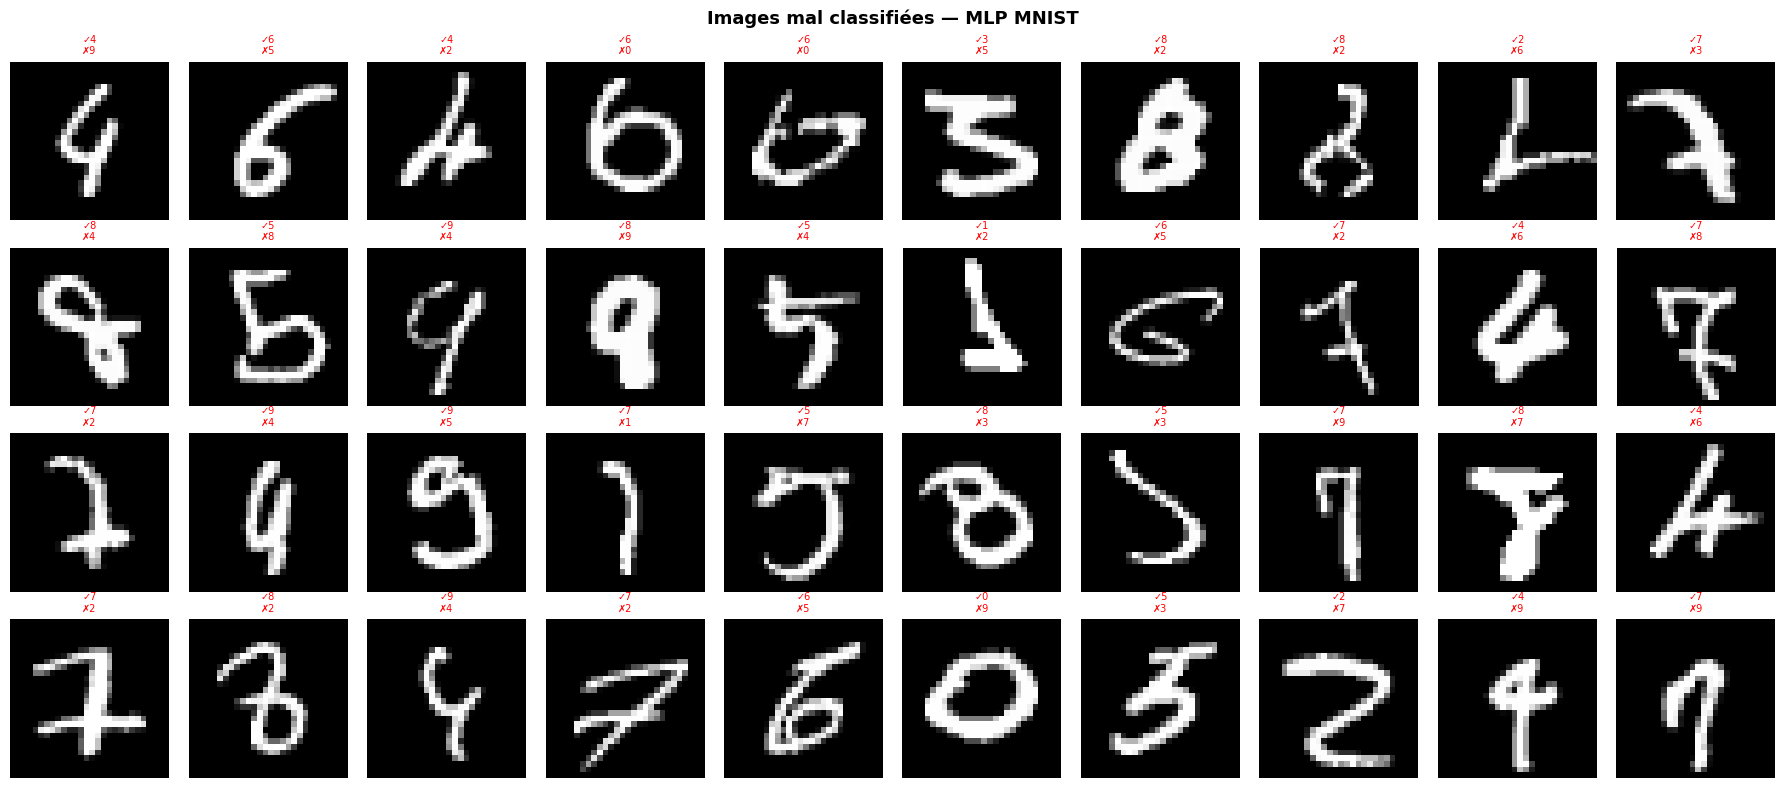

In [10]:
# Collecter les images mal classifiées avec leurs probabilités
model.eval()
wrong_imgs, wrong_true, wrong_pred, wrong_proba = [], [], [], []

with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b_dev = X_b.to(device)
        logits   = model(X_b_dev)
        probs    = torch.softmax(logits, dim=1).cpu()
        preds    = logits.argmax(dim=1).cpu()
        mask     = preds != y_b
        wrong_imgs.extend(X_b[mask])
        wrong_true.extend(y_b[mask].numpy())
        wrong_pred.extend(preds[mask].numpy())
        wrong_proba.extend(probs[mask].numpy())

print(f"Images mal classifiées : {len(wrong_imgs)} / {len(test_ds)}")
print(f"Taux d'erreur          : {len(wrong_imgs)/len(test_ds)*100:.2f}%")

# Afficher les 40 premières erreurs
n_show = min(40, len(wrong_imgs))
fig, axes = plt.subplots(4, 10, figsize=(18, 8))
fig.suptitle('Images mal classifiées — MLP MNIST', fontsize=13, fontweight='bold')

for idx in range(n_show):
    ax  = axes[idx // 10][idx % 10]
    img = wrong_imgs[idx].squeeze().numpy()
    # dénormalisation pour affichage
    img = img * 0.3081 + 0.1307
    ax.imshow(img, cmap='gray')
    ax.set_title(f"✓{wrong_true[idx]}\n✗{wrong_pred[idx]}", fontsize=7,
                 color='red')
    ax.axis('off')

plt.tight_layout()
plt.savefig('mnist_errors.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Sauvegarde du modèle & Inférence sur des images individuelles

Modèle sauvegardé : mlp_mnist_classifier.pth


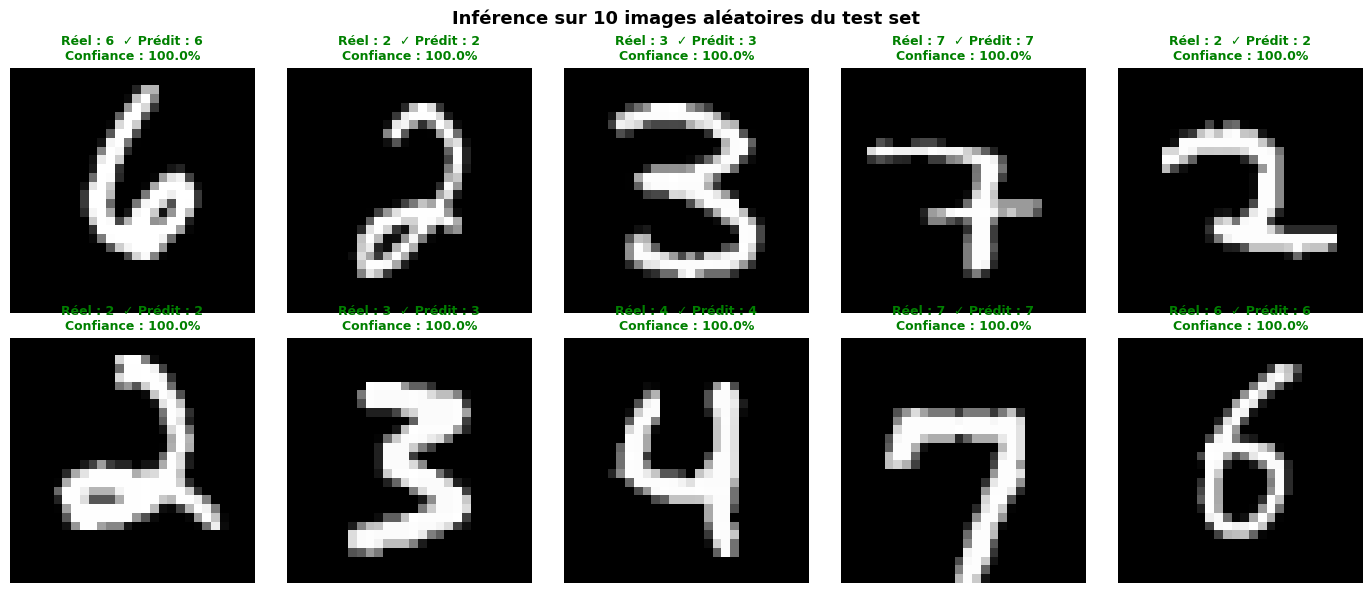


  RÉSUMÉ FINAL
  Epochs entraînés  : 50
  Test Accuracy     : 98.68%
  Best val_loss     : 0.0474
  Paramètres totaux : 569,226
  Fichier modèle    : mlp_mnist_classifier.pth


In [11]:
# ─── Sauvegarde ───────────────────────────────────────────────────────────────
torch.save(model.state_dict(), 'mlp_mnist_classifier.pth')
print("Modèle sauvegardé : mlp_mnist_classifier.pth")


# ─── Inférence sur 10 images aléatoires du test set ──────────────────────────
model.eval()
indices  = np.random.choice(len(test_ds), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Inférence sur 10 images aléatoires du test set', fontsize=13, fontweight='bold')

for plot_idx, ds_idx in enumerate(indices):
    img_tensor, true_label = test_ds[ds_idx]
    img_input = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(img_input)
        probs  = torch.softmax(logits, dim=1).cpu().squeeze().numpy()
        pred   = probs.argmax()

    ax = axes[plot_idx // 5][plot_idx % 5]
    img_show = img_tensor.squeeze().numpy() * 0.3081 + 0.1307
    ax.imshow(img_show, cmap='gray')

    color  = 'green' if pred == true_label else 'red'
    status = '✓' if pred == true_label else '✗'
    ax.set_title(
        f"Réel : {true_label}  {status} Prédit : {pred}\n"
        f"Confiance : {probs[pred]*100:.1f}%",
        fontsize=9, color=color, fontweight='bold'
    )
    ax.axis('off')

plt.tight_layout()
plt.savefig('mnist_inference.png', dpi=150, bbox_inches='tight')
plt.show()

# ─── Résumé final ─────────────────────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"  RÉSUMÉ FINAL")
print(f"{'='*50}")
print(f"  Epochs entraînés  : {len(history['train_loss'])}")
print(f"  Test Accuracy     : {test_acc*100:.2f}%")
print(f"  Best val_loss     : {best_val_loss:.4f}")
print(f"  Paramètres totaux : {sum(p.numel() for p in model.parameters()):,}")
print(f"  Fichier modèle    : mlp_mnist_classifier.pth")
print(f"{'='*50}")